# Học tổ hợp: Boosting

*Bài 9, mục 9.2.1.* Boosting huấn luyện các mô hình yếu **tuần tự**, mô hình sau tập trung sửa lỗi của các mô hình trước.

## 1. AdaBoost cài đặt từ đầu

Nhãn $y_i \in \{-1, +1\}$, mô hình yếu là cây một tầng (decision stump). Khởi tạo trọng số $w_i = 1/N$. Ở vòng $t$:
1. Huấn luyện $h_t$ với trọng số mẫu $w_i$.
2. Sai số có trọng số $\varepsilon_t = \sum_{i: h_t(\mathbf{x}_i) \ne y_i} w_i$.
3. Trọng số mô hình $\alpha_t = \frac{1}{2}\ln\frac{1 - \varepsilon_t}{\varepsilon_t}$.
4. Cập nhật $w_i \leftarrow w_i\,e^{-\alpha_t y_i h_t(\mathbf{x}_i)}$ rồi chuẩn hóa để tổng bằng 1: mẫu sai được tăng trọng số, mẫu đúng giảm.

Dự đoán cuối: $H(\mathbf{x}) = \text{sgn}\left(\sum_t \alpha_t h_t(\mathbf{x})\right)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

x = np.arange(10).reshape(-1, 1).astype(float)      # 10 điểm một chiều: 0, 1, ..., 9
y = np.array([1, 1, 1, -1, -1, -1, 1, 1, 1, -1])
print('x:', x.ravel().astype(int))
print('y:', y)

x: [0 1 2 3 4 5 6 7 8 9]
y: [ 1  1  1 -1 -1 -1  1  1  1 -1]


In [2]:
def adaboost(X, y, T):
    N = len(y)
    w = np.full(N, 1 / N)                    # trọng số mẫu ban đầu
    stumps, alphas = [], []
    for t in range(T):
        stump = DecisionTreeClassifier(max_depth=1).fit(X, y, sample_weight=w)
        pred = stump.predict(X)
        error = w[pred != y].sum()           # sai số có trọng số epsilon_t
        alpha = 0.5 * np.log((1 - error) / error)
        print('Vòng %d: ngưỡng x <= %.1f, mẫu sai %s, epsilon = %.3f, alpha = %.3f'
              % (t + 1, stump.tree_.threshold[0], np.flatnonzero(pred != y).tolist(), error, alpha))
        w = w * np.exp(-alpha * y * pred)    # tăng trọng số mẫu sai, giảm mẫu đúng
        w = w / w.sum()
        print('        trọng số mới:', w.round(3))
        stumps.append(stump)
        alphas.append(alpha)
    return stumps, alphas


def adaboost_predict(stumps, alphas, X):
    score = sum(alpha * stump.predict(X) for stump, alpha in zip(stumps, alphas))
    return np.sign(score)


stumps, alphas = adaboost(x, y, T=3)
for t in range(1, 4):
    acc = (adaboost_predict(stumps[:t], alphas[:t], x) == y).mean()
    print('Kết hợp %d cây một tầng: độ chính xác %.1f' % (t, acc))

Vòng 1: ngưỡng x <= 2.5, mẫu sai [6, 7, 8], epsilon = 0.300, alpha = 0.424
        trọng số mới: [0.071 0.071 0.071 0.071 0.071 0.071 0.167 0.167 0.167 0.071]
Vòng 2: ngưỡng x <= 8.5, mẫu sai [3, 4, 5], epsilon = 0.214, alpha = 0.650
        trọng số mới: [0.045 0.045 0.045 0.167 0.167 0.167 0.106 0.106 0.106 0.045]
Vòng 3: ngưỡng x <= 5.5, mẫu sai [0, 1, 2, 9], epsilon = 0.182, alpha = 0.752
        trọng số mới: [0.125 0.125 0.125 0.102 0.102 0.102 0.065 0.065 0.065 0.125]
Kết hợp 1 cây một tầng: độ chính xác 0.7
Kết hợp 2 cây một tầng: độ chính xác 0.7
Kết hợp 3 cây một tầng: độ chính xác 1.0


Mỗi cây một tầng chỉ đúng 70% (chia một ngưỡng), nhưng kết hợp 3 cây có trọng số phân loại đúng toàn bộ 10 điểm.

## 2. AdaBoost với scikit-learn

In [3]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
stump = DecisionTreeClassifier(max_depth=1).fit(X_train, y_train)
ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=200, random_state=0).fit(X_train, y_train)
print('Một cây một tầng       : kiểm tra %.4f' % stump.score(X_test, y_test))
print('AdaBoost 200 cây 1 tầng: kiểm tra %.4f' % ada.score(X_test, y_test))

Một cây một tầng       : kiểm tra 0.8889
AdaBoost 200 cây 1 tầng: kiểm tra 0.9591


## 3. Gradient Boosting: học phần dư

Với hồi quy và MSE, Gradient Boosting bắt đầu từ dự đoán hằng $F_0 = \bar{y}$; mỗi vòng huấn luyện một cây nhỏ $h_t$ dự đoán **phần dư** $r_i = y_i - F_{t-1}(\mathbf{x}_i)$ (chính là hướng ngược gradient của MSE), rồi cập nhật $F_t = F_{t-1} + \nu\,h_t$ với tốc độ học $\nu$.

In [4]:
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(0)
x_reg = np.sort(rng.uniform(0, 6, 80)).reshape(-1, 1)
y_reg = np.sin(x_reg).ravel() + rng.normal(0, 0.2, 80)
learning_rate = 0.5                          # tốc độ học nu
F = np.full_like(y_reg, y_reg.mean())        # F_0: dự đoán hằng
trees = []
for t in range(1, 51):
    residual = y_reg - F                     # phần dư = -gradient của MSE
    tree = DecisionTreeRegressor(max_depth=2).fit(x_reg, residual)
    F = F + learning_rate * tree.predict(x_reg)
    trees.append(tree)
    if t in [1, 2, 5, 10, 50]:
        print('Sau %2d cây: MSE huấn luyện = %.4f' % (t, np.mean((y_reg - F)**2)))

Sau  1 cây: MSE huấn luyện = 0.1782
Sau  2 cây: MSE huấn luyện = 0.0785
Sau  5 cây: MSE huấn luyện = 0.0270
Sau 10 cây: MSE huấn luyện = 0.0147
Sau 50 cây: MSE huấn luyện = 0.0016


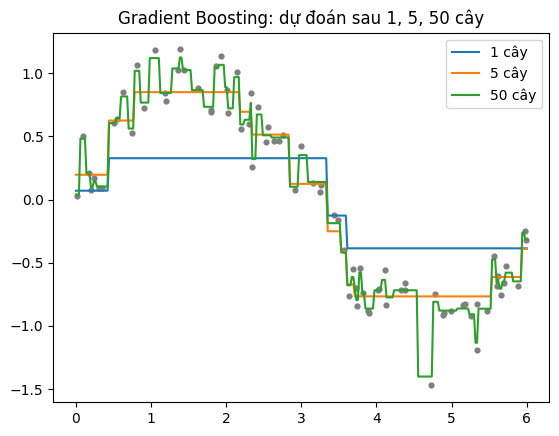

In [5]:
x_line = np.linspace(0, 6, 300).reshape(-1, 1)
plt.scatter(x_reg, y_reg, s=12, color='gray')
for n in [1, 5, 50]:
    pred = y_reg.mean() + learning_rate * sum(tree.predict(x_line) for tree in trees[:n])
    plt.plot(x_line, pred, label='%d cây' % n)
plt.legend(); plt.title('Gradient Boosting: dự đoán sau 1, 5, 50 cây')
plt.show()

## 4. Gradient Boosting với scikit-learn

In [6]:
from sklearn.ensemble import GradientBoostingClassifier

for learning_rate in [1.0, 0.1]:
    gb = GradientBoostingClassifier(n_estimators=200, learning_rate=learning_rate, max_depth=3, random_state=0)
    gb.fit(X_train, y_train)
    print('Gradient Boosting, learning_rate = %.1f: huấn luyện %.4f, kiểm tra %.4f'
          % (learning_rate, gb.score(X_train, y_train), gb.score(X_test, y_test)))

Gradient Boosting, learning_rate = 1.0: huấn luyện 1.0000, kiểm tra 0.9357


Gradient Boosting, learning_rate = 0.1: huấn luyện 1.0000, kiểm tra 0.9415
